# Week 2: Group your notes

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime. The outputs below are from 43 public Hacker News comments in which people describe the chairs they sit on.

## 1. Setup

This loads a small embedding model (all-MiniLM-L6-v2), which takes about a minute.

In [1]:
import html, re, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install sentence-transformers
import numpy as np, requests
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")
print("ready")

ready


## 2. Your notes

With USE_EXAMPLE = True, it downloads the 43 comments from Hacker News. To use your own notes, set it to False and paste them into MY_NOTES, one note per line (e.g., one thing a person said in an interview).

In [2]:
USE_EXAMPLE = True  # True: 43 public Hacker News comments about chairs. False: paste your own notes below.

MY_NOTES = """
Paste one note per line (e.g., one thing a person said in an interview).
"""

if USE_EXAMPLE:
    ids = [9276303, 8268551, 20371396, 12652827, 12652893, 385017, 24319665, 24320756, 3875029, 2755001,
           23547303, 14856355, 40940250, 18489495, 8272268, 2995324, 28208184, 9222124, 5491051, 7395942,
           2996497, 6289439, 49971395, 598225, 30490143, 8237292, 758029, 5645057, 5644533, 6568695,
           29598935, 20114164, 1987751, 30955863, 44116988, 35941216, 20371323, 30680619, 6013416, 15127360,
           20372719, 37970172, 6564209]
    notes = []
    for i in ids:
        item = requests.get(f"https://hacker-news.firebaseio.com/v0/item/{i}.json", timeout=30).json() or {}
        t = html.unescape(re.sub(r"<[^>]+>", " ", item.get("text", "")))
        notes.append(re.sub(r"\s+", " ", t).strip())
    print("downloaded", len(notes), "comments from news.ycombinator.com")
else:
    notes = [l.strip() for l in MY_NOTES.strip().splitlines() if l.strip()]
    print(len(notes), "notes")

downloaded 43 comments from news.ycombinator.com


## 3. Embed your notes

Each note becomes a list of 384 numbers, and notes that mean similar things get similar numbers.

In [3]:
E = model.encode(notes, normalize_embeddings=True)
print(E.shape[0], "notes, each as", E.shape[1], "numbers")

43 notes, each as 384 numbers


## 4. Groups

It groups the notes into K groups (4 to start) and prints the three notes closest to the middle of each group. Read every note in a group before you name it. A group can mix two ideas. You can change K and run the cell again.

In [4]:
K = 4  # how many groups to make
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(E)
for j in range(K):
    idx = np.where(km.labels_ == j)[0]
    closest = idx[np.argsort(((E[idx] - km.cluster_centers_[j]) ** 2).sum(1))]
    print(f"\nGroup {j + 1} ({len(idx)} notes). The three closest to the middle of the group:")
    for i in closest[:3]:
        print("  -", notes[i][:160] + ("…" if len(notes[i]) > 160 else ""))


Group 1 (5 notes). The three closest to the middle of the group:
  - Traditional furniture had the same problem but being too ornate instead. How many fancy hand carved wood chairs with 90 degree straight up backs exist? Painful …
  - One of the best things about the Aeron chairs is that nearly every part is replaceable, so there's nothing to stop you replacing the hydraulics and reviving the…
  - I'm 1.9 meters and have recently put on weight, several of my modern dining room chairs have disassembled on me spontaneously when I sat on them hard or rocked …

Group 2 (17 notes). The three closest to the middle of the group:
  - I went from an office chair with arms I would lean on, to a regular folding steel chair with a cushion on it. It has forced me to hold myself upright and has th…
  - I use a regular office chair without the arm rests because i sit cross-legged. Works much better for me then regular sitting.
  - I built a standing desk and wanted to be able to both stand and sit. 

## 5. Map

Each dot is one note, colored by its group. It also saves groups.csv with every note and its group. You can then open it in a spreadsheet and name each group.

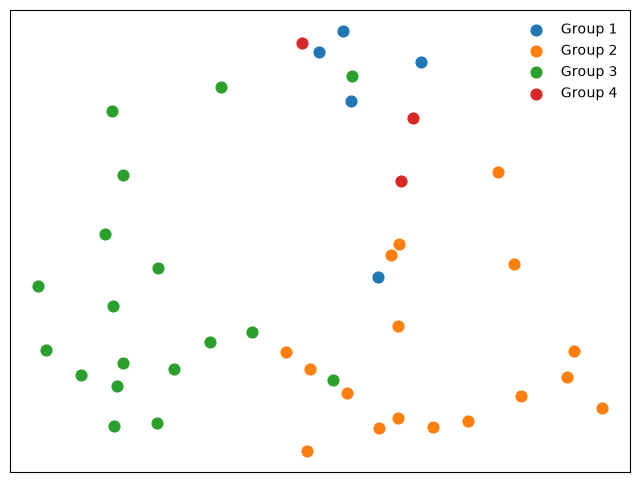

saved groups.csv and groups.png


In [5]:
xy = PCA(n_components=2, random_state=0).fit_transform(E)
fig, ax = plt.subplots(figsize=(8, 6))
for j in range(K):
    m = km.labels_ == j
    ax.scatter(xy[m, 0], xy[m, 1], s=60, label=f"Group {j + 1}")
ax.legend(frameon=False)
ax.set_xticks([]); ax.set_yticks([])
plt.savefig("groups.png", dpi=120, bbox_inches="tight")
plt.show()
with open("groups.csv", "w") as f:
    f.write("group,note\n")
    for g, n in zip(km.labels_, notes):
        f.write(f'{g + 1},"{n.replace(chr(34), chr(39))}"\n')
print("saved groups.csv and groups.png")